## ДЗ №2. Матричные факторизации

#### В этой домашке вам предстоит реализовать некоторые базовые модели матричной факторизации

#### Дата выдачи: 17.02.25

#### Мягкий дедлайн: 02.03.25 23:59 MSK

#### Жесткий дедлайн: 09.03.25 23:59 MSK

В этом задании мы будем работать с классическим для рекоендательных систем датасетом [MovieLens 1M](https://grouplens.org/datasets/movielens/1m/). Датасет содержит рейтинги оценки для 4000 фильмов от 6000 пользователей. Более подробное описание можете найти на странице с датасетом и в README файле

In [1]:
from pathlib import Path
from urllib.request import urlopen
import ssl
import certifi
import hashlib
from zipfile import ZipFile

cache_dir = Path.home() / '.cache' / 'recsys-course' / 'ml-1m'
cache_dir.mkdir(parents=True, exist_ok=True)
archive = cache_dir / 'ml-1m.zip'
if not archive.exists():
    context = ssl.create_default_context(cafile=certifi.where())
    with urlopen('https://files.grouplens.org/datasets/movielens/ml-1m.zip', context=context) as response:
        archive.write_bytes(response.read())
expected_sha256 = 'a6898adb50b9ca05aa231689da44c217cb524e7ebd39d264c56e2832f2c54e20'
if hashlib.sha256(archive.read_bytes()).hexdigest() != expected_sha256:
    raise ValueError('Контрольная сумма архива MovieLens не совпадает')
with ZipFile(archive) as z:
    for name in ('ratings.dat', 'movies.dat', 'README'):
        target = cache_dir / name
        if not target.exists():
            target.write_bytes(z.read('ml-1m/' + name))
print((cache_dir / 'README').read_text(encoding='latin-1')[:1000])

SUMMARY

These files contain 1,000,209 anonymous ratings of approximately 3,900 movies 
made by 6,040 MovieLens users who joined MovieLens in 2000.

USAGE LICENSE

Neither the University of Minnesota nor any of the researchers
involved can guarantee the correctness of the data, its suitability
for any particular purpose, or the validity of results based on the
use of the data set.  The data set may be used for any research
purposes under the following conditions:

     * The user may not state or imply any endorsement from the
       University of Minnesota or the GroupLens Research Group.

     * The user must acknowledge the use of the data set in
       publications resulting from the use of the data set
       (see below for citation information).

     * The user may not redistribute the data without separate
       permi


In [2]:
import pandas as pd
import numpy as np
from typing import Union

In [3]:
df = pd.read_csv(cache_dir / 'ratings.dat', sep='::', names=['user_id', 'item_id', 'rating', 'timestamp'], engine='python')
df['datetime'] = pd.to_datetime(df['timestamp'], unit='s')
df.drop('timestamp', axis=1, inplace=True)
df.head()

,user_id,item_id,rating,datetime
0,1,1193,5,2000-12-31 22:12:40
1,1,661,3,2000-12-31 22:35:09
2,1,914,3,2000-12-31 22:32:48
3,1,3408,4,2000-12-31 22:04:35
4,1,2355,5,2001-01-06 23:38:11


In [4]:
# Частоты фильмов считаем только на обучающем периоде: будущие оценки
# не должны влиять на состав каталога.
train_end = '2000-12-01'
value_counts = df.loc[df['datetime'] < train_end, 'item_id'].value_counts()
filtered_values = value_counts[value_counts > 20].index
df = df[df['item_id'].isin(filtered_values)].copy()

In [5]:
train_end = '2000-12-01'
df_train = df[df['datetime'] < train_end].copy()
df_test = df[df['datetime'] >= train_end].copy()
df_train.shape, df_test.shape

((785020, 4), (206005, 4))

In [6]:
train_users = df_train['user_id'].unique()
train_items = df_train['item_id'].unique()

df_test = df_test[df_test['user_id'].isin(train_users)]
df_test = df_test[df_test['item_id'].isin(train_items)]
df_test.shape

(105493, 4)

In [7]:
from sklearn.preprocessing import LabelEncoder

user_le = LabelEncoder()
item_le = LabelEncoder()

df_train['user_id'] = user_le.fit_transform(df_train['user_id'])
df_train['item_id'] = item_le.fit_transform(df_train['item_id'])

df_test['user_id'] = user_le.transform(df_test['user_id'])
df_test['item_id'] = item_le.transform(df_test['item_id'])

In [8]:
df_train['user_id'].nunique(), df_train['user_id'].max()
df_train['item_id'].nunique(), df_train['item_id'].max()

(2864, 2863)

##### Задание 1. Напишем функцию, которая превратит датафрейм в матрицу интеракций. В функции df_to_matrix реализуйте функцию, которая принимает датафрейм и возвращает np.array матрицу интеракций. В функции df_to_coo реализуйте функцию, которая принимает датафрейм и возвращает разреженную матрицу интеракций в coo_array формате

In [9]:
def df_to_matrix(df: pd.DataFrame) -> np.ndarray:
    #your code here
    result = np.zeros((df.user_id.max() + 1, df.item_id.max() + 1), dtype=float)
    result[df.user_id.to_numpy(), df.item_id.to_numpy()] = df.rating.to_numpy()
    return result #shape ~ [n_users, n_items]

In [10]:
interactions = df_to_matrix(df_train)

In [11]:
from scipy.sparse import coo_array

def df_to_coo(df: pd.DataFrame) -> coo_array:
    #your code here
    result = coo_array((df.rating.to_numpy(dtype=float),
                        (df.user_id.to_numpy(), df.item_id.to_numpy())),
                       shape=(df.user_id.max() + 1, df.item_id.max() + 1))
    return result # coo_array

In [12]:
coo_interactions = df_to_coo(df_train)

In [13]:
assert (interactions != 0).sum() == df_train.shape[0]
assert np.allclose(coo_interactions.toarray(), interactions)
# Фильтр по train меняет индексы LabelEncoder, поэтому проверяем те же
# наблюдения по исходным идентификаторам. Фильм 3935 не проходит новый фильтр.
for original_user, original_item, expected in [(3045, 1617, 5), (2230, 538, 3)]:
    user = user_le.transform([original_user])[0]
    item = item_le.transform([original_item])[0]
    assert interactions[user, item] == expected
sample = pd.DataFrame({'user_id': [0, 0, 1], 'item_id': [0, 2, 1], 'rating': [3, 5, 4]})
expected = np.array([[3, 0, 5], [0, 4, 0]])
assert np.array_equal(df_to_matrix(sample), expected)
assert np.array_equal(df_to_coo(sample).toarray(), expected)

##### Задание 2.1. Рассмотрим [SVD](https://en.wikipedia.org/wiki/Singular_value_decomposition). Возьмите готовую реализуцию алгоритма из numpy.linalg или из scipy.linalg и примените алгоритм к матрицам интеракций, полученным в первом задании. Для работы со sparse матрицей обычная реализация svd не подойдет и нужно будет воспользоваться scipy.sparse.linalg.svds. Вам нужно разложить матрицу интеракций на 3 матрицы U, S, V, а затем перемножить их и восстановить изначальную матрицу. При полном разложении исходная матрица должна восстанавливаться максимально хорошо

In [14]:
from scipy.sparse import issparse
from scipy.sparse.linalg import svds
from threadpoolctl import threadpool_limits

# Ограничение числа потоков снижает накладные расходы BLAS на этом датасете.
threadpool_limits(limits=4, user_api='blas')

def make_svd(interractions: Union[np.ndarray, coo_array], n_singular_values: int = -1):
    # Для плотной и разреженной матриц используем соответствующие реализации.
    #your code here
    limit = min(interractions.shape)
    if issparse(interractions):
        k = limit - 1 if n_singular_values == -1 else n_singular_values
        if not 1 <= k < limit:
            raise ValueError('Для sparse SVD число компонент должно быть от 1 до min(shape)-1')
        U, s, V = svds(interractions.astype(float), k=k, random_state=42)
        order = np.argsort(s)[::-1]
        U, s, V = U[:, order], s[order], V[order]
    else:
        U, s, V = np.linalg.svd(interractions, full_matrices=False)
        k = len(s) if n_singular_values == -1 else n_singular_values
        if not 1 <= k <= limit:
            raise ValueError('Неверное число компонент')
        U, s, V = U[:, :k], s[:k], V[:k]
    S = np.diag(s)
    return U, S, V

In [15]:
U, S, V = make_svd(interactions)
assert np.allclose(U @ S @ V, interactions)

In [16]:
U1, S1, V1 = make_svd(interactions, 10)
U, S, V = make_svd(coo_interactions, 10)
assert np.allclose(U1 @ S1 @ V1, U @ S @ V)

##### Задание 2.2. Теперь попробуем сделать рекомендации с помощью SVD. Мы научились восстанавливать исходную матрицу с помощью разложения, теперь же мы хотим порекомендовать пользователю айтемы, которые будут для него максимально релевантны(в восстановленной матрице у них будет самый высокий скор). Для каждого пользователя нужно будет найти индексы айтемов, которые имеют максимальный скор. При этом стоит обратить внимание, что мы не хотим рекомендовать пользователю айтемы, с которыми он уже взаимодействовал

In [17]:
def top_unseen(scores, seen, top_k=100):
    scores = np.asarray(scores).copy()
    rows, cols = seen.nonzero() if issparse(seen) else np.nonzero(seen)
    scores[rows, cols] = -np.inf
    if top_k > scores.shape[1] or np.any(np.isfinite(scores).sum(axis=1) < top_k):
        raise ValueError('Недостаточно непросмотренных фильмов для top_k')
    candidates = np.argpartition(-scores, top_k - 1, axis=1)[:, :top_k]
    order = np.argsort(-np.take_along_axis(scores, candidates, axis=1), axis=1)
    return np.take_along_axis(candidates, order, axis=1)

def make_svd_recommendations(interractions: Union[np.ndarray, coo_array], n_singular_values: int = -1, top_k: int = 100):
    #your code here
    U, S, V = make_svd(interractions, n_singular_values)
    recommendations = top_unseen((U @ S) @ V, interractions, top_k)
    return recommendations #shape ~ [n_users, top_k]

In [18]:
recs = make_svd_recommendations(interactions, -1, 100)
assert recs.shape == (interactions.shape[0], 100)

##### Задание 2.3. Теперь давайте посмотрим как будет зависеть качетво рекомендаций, от количества сингулярных чисел, которые мы возьмем в SVD разложении. Переберите n_singular_values из списка [1, 10, 50, 200, 1000] и посмотрите как будет изменяться метрика NDCG на тестовом датасете для таких рекомендаций и как будет меняться время вычисления. Для каждого графики зависимости метрики NDCG от n_singular_values и времени работы алгоритма от n_singular_values(Время работы будет меняться только для sparse-матрицы, стоит запускать алгоритм именно для нее)

In [19]:
import time
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix

# Тест содержит только пользователей и фильмы, известные в обучении.
test_users = np.sort(df_test.user_id.unique())
test_matrix = csr_matrix((df_test.rating, (df_test.user_id, df_test.item_id)), shape=interactions.shape)

def ndcg_at_k(recommendations, k=100):
    # Усреднение по пользователям теста, релевантность — исходная оценка 1–5.
    discounts = 1 / np.log2(np.arange(2, k + 2))
    values = []
    for user in test_users:
        truth = test_matrix.getrow(user).toarray().ravel()
        gain = np.exp2(truth) - 1
        ideal = np.sort(gain)[::-1][:k]
        values.append((gain[recommendations[user, :k]] @ discounts) / (ideal @ discounts))
    return float(np.mean(values))

def plot_graphs(interractions: Union[np.ndarray, coo_array], top_k: int = 100):
    #your code here
    results = []
    for n_singular_values in [1, 10, 50, 200, 1000]:
        #your code here
        start = time.perf_counter()
        recs = make_svd_recommendations(interractions, n_singular_values, top_k)
        elapsed = time.perf_counter() - start
        results.append((n_singular_values, ndcg_at_k(recs, top_k), elapsed))
        print(f'k={n_singular_values}: NDCG@{top_k}={results[-1][1]:.4f}, {elapsed:.1f} с', flush=True)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, column, ylabel in zip(axes, (1, 2), ('NDCG@100', 'Время, с')):
        ax.plot([r[0] for r in results], [r[column] for r in results], marker='o')
        ax.set_xscale('log')
        ax.set_xlabel('Число сингулярных чисел')
        ax.set_ylabel(ylabel)
        ax.grid(True)
    plt.tight_layout()
    plt.show()
    return pd.DataFrame(results, columns=['factors', 'ndcg', 'seconds'])

k=1: NDCG@100=0.2162, 0.6 с


k=10: NDCG@100=0.2487, 0.5 с


k=50: NDCG@100=0.2259, 0.9 с


k=200: NDCG@100=0.1605, 3.1 с


k=1000: NDCG@100=0.0483, 22.0 с


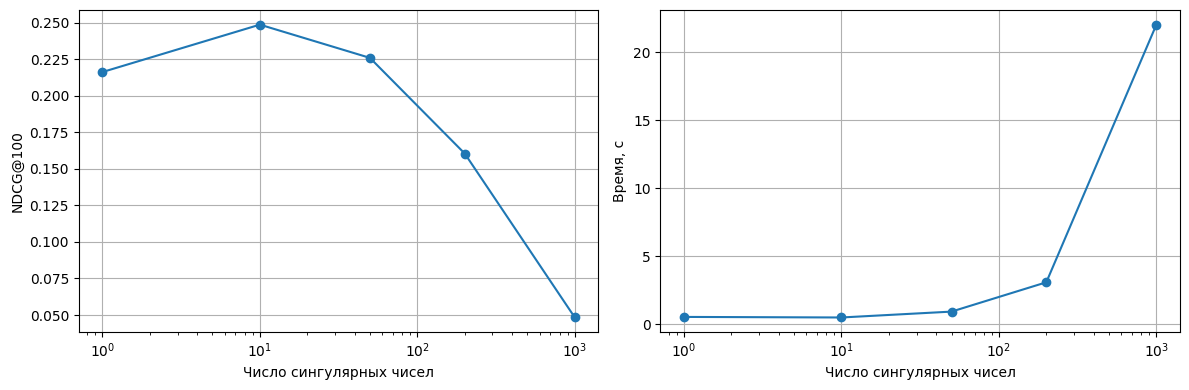

,factors,ndcg,seconds
0,1,0.216231,0.550218
1,10,0.248661,0.508946
2,50,0.225924,0.940344
3,200,0.160475,3.093782
4,1000,0.048334,22.020827


In [20]:
svd_results = plot_graphs(coo_interactions)
svd_results

##### Задание 3.1. Перейдем к [ALS](http://yifanhu.net/PUB/cf.pdf). Возьмем реализацию iALS из библиотеки [implicit](https://benfred.github.io/implicit/api/models/cpu/als.html). Обучите ALS на нашем датасете, сделайте top_k рекомендации для юзеров из тестового датасета, и сравните метрики ALS с метриками, которые получились в SVD. Попробуйте перебрать гиперпараметры и найдите оптимальное число факторов, коэффициент alpha и коэффициент регуляризации.

In [21]:
from implicit.als import AlternatingLeastSquares

def train_als(interractions, n_factors=100, alpha=1.0, regularization=0.01, iterations=15):
    matrix = csr_matrix(interractions, dtype=np.float32)
    matrix.indices = matrix.indices.astype(np.int32)
    matrix.indptr = matrix.indptr.astype(np.int32)
    model = AlternatingLeastSquares(factors=n_factors, alpha=alpha, regularization=regularization,
                                    iterations=iterations, random_state=42, num_threads=4, use_gpu=False)
    with threadpool_limits(limits=1, user_api='blas'):
        model.fit(matrix, show_progress=False)
    return model

def als_recommendations(model, interractions, top_k=100):
    matrix = csr_matrix(interractions, dtype=np.float32)
    ids = np.arange(matrix.shape[0])
    recommendations, _ = model.recommend(ids, matrix, N=top_k, filter_already_liked_items=True)
    return recommendations

def make_als_recommendations(interractions: Union[np.ndarray, coo_array], top_k: int = 100,
                             n_factors: int = 100, alpha: float = 1.0, regularization: float = 0.01):
    #your code here
    model = train_als(interractions, n_factors, alpha, regularization)
    recommendations = als_recommendations(model, interractions, top_k)
    return recommendations #shape ~ [n_users, top_k]

C:\Users\Иван\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [22]:
recs = make_als_recommendations(interactions)
assert recs.shape == (interactions.shape[0], 100)
print(f'ALS по умолчанию: NDCG@100 = {ndcg_at_k(recs):.4f}')

# Подбор на отдельной временной валидации, тест не участвует в выборе параметров.
val_start = '2000-11-01'
fit_df = df_train[df_train.datetime < val_start]
val_df = df_train[df_train.datetime >= val_start]
# Каталог и пользователи для валидации определяются только по fit-периоду.
fit_item_counts = fit_df.item_id.value_counts()
fit_items = fit_item_counts[fit_item_counts > 20].index
fit_df = fit_df[fit_df.item_id.isin(fit_items)]
val_df = val_df[val_df.item_id.isin(fit_items) & val_df.user_id.isin(fit_df.user_id)]
fit_matrix = csr_matrix((fit_df.rating, (fit_df.user_id, fit_df.item_id)), shape=interactions.shape)
val_matrix = csr_matrix((val_df.rating, (val_df.user_id, val_df.item_id)), shape=interactions.shape)
val_users = np.intersect1d(np.unique(val_df.user_id), np.unique(fit_df.user_id))
def val_ndcg(recs):
    discounts = 1 / np.log2(np.arange(2, 102))
    values = []
    for user in val_users:
        gain = np.exp2(val_matrix.getrow(user).toarray().ravel()) - 1
        values.append((gain[recs[user]] @ discounts) / (np.sort(gain)[::-1][:100] @ discounts))
    return float(np.mean(values))
search = []
for factors in (20, 50):
    for alpha in (1.0, 10.0):
        for reg in (0.1, 1.0):
            model = train_als(fit_matrix, factors, alpha, reg)
            score = val_ndcg(als_recommendations(model, fit_matrix))
            search.append((factors, alpha, reg, score))
search_results = pd.DataFrame(search, columns=['factors', 'alpha', 'regularization', 'val_ndcg'])
best = search_results.sort_values('val_ndcg', ascending=False).iloc[0]
best_params = dict(n_factors=int(best.factors), alpha=float(best.alpha), regularization=float(best.regularization))
best_als = train_als(coo_interactions, **best_params)
best_als_recs = als_recommendations(best_als, coo_interactions)
print('Лучшие параметры на валидации:', best_params)
print(f'ALS на тесте: NDCG@100 = {ndcg_at_k(best_als_recs):.4f}')
print('SVD на тесте:')
print(svd_results.to_string(index=False))
search_results

C:\Users\Иван\AppData\Local\Programs\Python\Python310\lib\site-packages\implicit\cpu\als.py:96: RuntimeWarning: OpenBLAS is configured to use 4 threads. It is highly recommended to disable its internal threadpool by setting the environment variable 'OPENBLAS_NUM_THREADS=1' or by calling 'threadpoolctl.threadpool_limits(1, "blas")'. Having OpenBLAS use a threadpool can lead to severe performance issues here.
  check_blas_config()


ALS по умолчанию: NDCG@100 = 0.1978


Лучшие параметры на валидации: {'n_factors': 20, 'alpha': 1.0, 'regularization': 1.0}
ALS на тесте: NDCG@100 = 0.2268
SVD на тесте:
 factors     ndcg   seconds
       1 0.216231  0.550218
      10 0.248661  0.508946
      50 0.225924  0.940344
     200 0.160475  3.093782
    1000 0.048334 22.020827


,factors,alpha,regularization,val_ndcg
0,20,1.0,0.1,0.128236
1,20,1.0,1.0,0.131998
2,20,10.0,0.1,0.111323
3,20,10.0,1.0,0.111044
4,50,1.0,0.1,0.117844
5,50,1.0,1.0,0.115685
6,50,10.0,0.1,0.102035
7,50,10.0,1.0,0.099900


##### Задание 3.2. Сделайте объяснение рекомендаций для нескольких юзеров(als.explain). Воспользуйтесь файлом movies.dat чтобы перейти от индексов фильмов к их названием

In [23]:
#your code here
movies = pd.read_csv(cache_dir / 'movies.dat', sep='::', engine='python', encoding='latin-1',
                     names=['movie_id', 'title', 'genres']).set_index('movie_id')
def movie_title(encoded_id):
    return movies.loc[item_le.inverse_transform([encoded_id])[0], 'title']

explain_matrix = csr_matrix(coo_interactions)
explain_matrix.indices = explain_matrix.indices.astype(np.int32)
explain_matrix.indptr = explain_matrix.indptr.astype(np.int32)
for user in test_users[:3]:
    item = int(best_als_recs[user, 0])
    total, contributions, _ = best_als.explain(int(user), explain_matrix, item, N=3)
    print(f'Пользователь {user_le.inverse_transform([user])[0]}: {movie_title(item)} (оценка {total:.3f})')
    for seen_item, contribution in contributions:
        print(f'  {movie_title(seen_item)}: вклад {contribution:.3f}')

Пользователь 670: North by Northwest (1959) (оценка 0.872)
  Airplane! (1980): вклад 0.057
  Casablanca (1942): вклад 0.054
  Almost Famous (2000): вклад 0.052
Пользователь 671: Chinatown (1974) (оценка 0.781)
  Rear Window (1954): вклад 0.063
  Vertigo (1958): вклад 0.058
  2001: A Space Odyssey (1968): вклад 0.053
Пользователь 673: Cider House Rules, The (1999) (оценка 1.375)
  Gladiator (2000): вклад 0.029
  Searching for Bobby Fischer (1993): вклад 0.028
  Almost Famous (2000): вклад 0.027


##### Задание 4. До этого мы работали с рейтингами, но как обсуждалось на лекции, implicit ALS отлично работает и с implicit фидбэком. Давайте попробуем преобразовать наш датасет(трейн и тест) следующим образом

1. Бинаризуем все рейтинги(заменим любую интеракцию пользователя на 1)
2. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на 0
3. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на -1
4. Заменим на 1 только рейтинги 4 и 5, а рейтинг ниже 4 заменим на -1 и добавим сглаживание по времени. То есть чем дальше была интеракция от максимальной даты трейна, тем с меньшим весом мы будем ее учитывать(например можно интеракции за последний месяц брать в исходном виде, и с каждым месяцем в прошлое умножать их на какой-нибудь коэффициент меньший 1). Таким образом более старые интеракции пользователя будут вносить меньший вклад в его интересы
5. Придумайте свой вариант(опционально)

Для каждой полученной матрицы обучите iALS и SVD и сравните их результаты между собой(преобразовывать нужно только обучающую выборку, тестовую оставляем неизменной)

In [24]:
#your code here
# Все преобразования выполняются только на train. Для маски просмотра сохраняем
# исходные интеракции, включая оценки, превращённые в ноль.
train_base = df_train.copy()
max_date = train_base.datetime.max()
age_months = (max_date - train_base.datetime).dt.total_seconds() / (30 * 24 * 3600)
strategies = {
    'Все взаимодействия': np.ones(len(train_base)),
    'Только оценки 4–5': (train_base.rating >= 4).astype(float),
    'Положительные и отрицательные': np.where(train_base.rating >= 4, 1.0, -1.0),
    'Со сглаживанием по времени': np.where(train_base.rating >= 4, 1.0, -1.0) * (0.9 ** age_months),
}
seen = csr_matrix(coo_interactions)
comparison = []
for name, values in strategies.items():
    matrix = csr_matrix((np.asarray(values), (train_base.user_id, train_base.item_id)), shape=interactions.shape)
    matrix.eliminate_zeros()
    model = train_als(matrix, **best_params)
    # Отрицательные и нулевые исходные оценки также исключаем из рекомендаций.
    als_scores = model.user_factors @ model.item_factors.T
    als_recs = top_unseen(als_scores, seen)
    U, S, V = make_svd(coo_array(matrix), 50)
    svd_recs = top_unseen((U @ S) @ V, seen)
    comparison.append((name, ndcg_at_k(als_recs), ndcg_at_k(svd_recs)))
comparison_df = pd.DataFrame(comparison, columns=['Преобразование', 'ALS NDCG@100', 'SVD NDCG@100'])
comparison_df

,Преобразование,ALS NDCG@100,SVD NDCG@100
0,Все взаимодействия,0.218647,0.207047
1,Только оценки 4–5,0.249377,0.233939
2,Положительные и отрицательные,0.249388,0.217738
3,Со сглаживанием по времени,0.249748,0.223019


##### Задание 5. iALS на numpy/torch. Давайте реализуем алгоритм iALS на нумпае или торче. Требуется реализовать алгорит, описанный в 4 части [статьи](http://yifanhu.net/PUB/cf.pdf). Обратите внимания на все оптимизации, которые они описывают в статье, чтобы сократить лишние вычисления. Hint: метрики у вашего алгоритма должны быть сравнимы с метриками ALS из библиотеки implicit

In [25]:
import torch

torch.set_num_threads(4)
class iALS:
    def __init__(self, n_factors: int = 100, alpha: float = 1.0, reg_coef=0.01):
        #your code here
        self.n_factors, self.alpha, self.reg_coef = n_factors, alpha, reg_coef

    def _update(self, matrix, fixed):
        # YᵀY — общая часть нормальных уравнений для всех пользователей.
        gram = fixed.T @ fixed + torch.eye(self.n_factors) * self.reg_coef
        result = torch.empty((matrix.shape[0], self.n_factors))
        for row in range(matrix.shape[0]):
            start, end = matrix.indptr[row:row+2]
            idx = matrix.indices[start:end]
            if not len(idx):
                result[row] = 0
                continue
            values = torch.from_numpy(matrix.data[start:end])
            factors = fixed[idx]
            confidence = 1 + self.alpha * values.abs()
            A = gram + factors.T @ ((confidence - 1)[:, None] * factors)
            b = factors.T @ (confidence * (values > 0))
            result[row] = torch.linalg.solve(A, b)
        return result

    def fit(self, interractions: np.ndarray, n_iterations: int = 10):
        #your code here
        # Hu et al.: C = 1 + alpha * |r|, предпочтение 1 при r > 0, иначе 0.
        self.interactions = csr_matrix(interractions, dtype=np.float32)
        self.interactions.eliminate_zeros()
        rng = np.random.default_rng(42)
        users = torch.tensor(rng.normal(0, 0.01, (self.interactions.shape[0], self.n_factors)), dtype=torch.float32)
        items = torch.tensor(rng.normal(0, 0.01, (self.interactions.shape[1], self.n_factors)), dtype=torch.float32)
        transposed = self.interactions.T.tocsr()
        for _ in range(n_iterations):
            users = self._update(self.interactions, items)
            items = self._update(transposed, users)
        self.user_factors, self.item_factors = users.numpy(), items.numpy()
        return self

    def predict(self, top_k: int = 100):
        #your code here
        predicts = top_unseen(self.user_factors @ self.item_factors.T, self.interactions, top_k)
        return predicts # shape ~ [n_users, top_k]

In [26]:
# Проверка оптимизированного обновления по прямым нормальным уравнениям.
small = csr_matrix(np.array([[2., 0., -1.], [0., 1., 0.]], dtype=np.float32))
fixed = torch.tensor([[0.2, 0.4], [0.6, -0.3], [-0.1, 0.5]])
check = iALS(n_factors=2, alpha=2.0, reg_coef=0.1)
actual = check._update(small, fixed).numpy()
for row in range(small.shape[0]):
    ratings = small.getrow(row).toarray().ravel()
    C = np.diag(1 + 2 * np.abs(ratings))
    Y = fixed.numpy()
    expected = np.linalg.solve(Y.T @ C @ Y + 0.1 * np.eye(2), Y.T @ C @ (ratings > 0))
    assert np.allclose(actual[row], expected, atol=1e-5)
print('Проверка нормальных уравнений пройдена.')

# implicit принимает готовый confidence, поэтому передаём 1 + alpha * |r|
# с исходным знаком и устанавливаем alpha=1. Число итераций одинаковое.
custom_params = dict(n_factors=20, alpha=1.0, regularization=0.1)
reference_confidence = csr_matrix(coo_interactions, dtype=np.float32).copy()
reference_confidence.data = np.sign(reference_confidence.data) * (1 + custom_params['alpha'] * np.abs(reference_confidence.data))
reference = train_als(reference_confidence, n_factors=20, alpha=1.0, regularization=0.1, iterations=10)
custom = iALS(n_factors=20, alpha=1.0, reg_coef=0.1).fit(interactions, n_iterations=10)
reference_score = ndcg_at_k(als_recommendations(reference, coo_interactions))
custom_score = ndcg_at_k(custom.predict())
print(f'implicit ALS: NDCG@100 = {reference_score:.4f}')
print(f'Собственная iALS: NDCG@100 = {custom_score:.4f}')

Проверка нормальных уравнений пройдена.


implicit ALS: NDCG@100 = 0.2225
Собственная iALS: NDCG@100 = 0.2223


In [27]:
best_svd = svd_results.loc[svd_results.ndcg.idxmax()]
best_strategy = comparison_df.loc[comparison_df['ALS NDCG@100'].idxmax()]
print(f"Лучший SVD в переборе: {int(best_svd.factors)} компонент, NDCG@100 = {best_svd.ndcg:.4f}.")
print(f"ALS с параметрами, выбранными на валидации: NDCG@100 = {ndcg_at_k(best_als_recs):.4f}.")
print(f"Среди преобразований лучший ALS: «{best_strategy['Преобразование']}», NDCG@100 = {best_strategy['ALS NDCG@100']:.4f}.")
print(f"При одинаковых параметрах собственная iALS: {custom_score:.4f}, implicit: {reference_score:.4f}.")

Лучший SVD в переборе: 10 компонент, NDCG@100 = 0.2487.
ALS с параметрами, выбранными на валидации: NDCG@100 = 0.2268.
Среди преобразований лучший ALS: «Со сглаживанием по времени», NDCG@100 = 0.2497.
При одинаковых параметрах собственная iALS: 0.2223, implicit: 0.2225.
